In [ ]:
!pip install fastf1 matplotlib pandas numpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 53.7 MB/s  0:00:00
  Attempting uninstall: msgpack
    Found existing installation: msgpack 1.2.3
    Uninstalling msgpack-1.2.3:
      Successfully uninstalled msgpack-1.2.3
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8/8 [fastf1]


In [ ]:
# ============================================================
# F1 Telemetry Explorer V2 - Shared Configuration
# Change these settings to analyze another race or driver
# ============================================================

import os
import fastf1

# ---------- Race and session ----------
YEAR = 2022
EVENT_NAME = "Saudi Arabian Grand Prix"
SESSION_CODE = "Q"                  # see SESSION_NAMES below for valid codes

# ---------- Drivers (three-letter, UPPERCASE abbreviations) ----------
DRIVER_1 = "LEC"                    # main driver, and first driver in comparisons
DRIVER_2 = "VER"                    # comparison driver
DRIVER_CODE = DRIVER_1              # same as DRIVER_1, so you only edit one place
AUTO_SELECT_TOP_TWO = True

# ---------- Cache ----------
CACHE_FOLDER = "/content/fastf1_cache"

# Friendly names for common session codes
SESSION_NAMES = {
    "FP1": "Practice 1", "FP2": "Practice 2", "FP3": "Practice 3",
    "Q": "Qualifying", "SQ": "Sprint Qualifying", "SS": "Sprint Shootout",
    "S": "Sprint", "R": "Race",
}

# ---------- Check the settings before anything else uses them ----------
config_problems = []

if not hasattr(fastf1.Cache, "configure"):
    config_problems.append(
        "This FastF1 version has no Cache.configure (needs 3.9.0 or newer). "
        "Run: !pip install --upgrade fastf1  then Runtime > Restart session."
    )
if not isinstance(YEAR, int) or YEAR < 2018:
    config_problems.append("YEAR should be a whole number from 2018 onwards (when FastF1 telemetry begins).")
if SESSION_CODE not in SESSION_NAMES:
    config_problems.append(f"Unknown SESSION_CODE '{SESSION_CODE}'. Try one of: {', '.join(SESSION_NAMES)}")
for code in (DRIVER_1, DRIVER_2):
    if not (isinstance(code, str) and len(code) == 3 and code.isalpha() and code.isupper()):
        config_problems.append(f"Driver code '{code}' should be three UPPERCASE letters, like 'LEC'.")
if DRIVER_1 == DRIVER_2:
    config_problems.append("DRIVER_1 and DRIVER_2 are the same driver - a comparison needs two different drivers.")

CONFIG_OK = len(config_problems) == 0   # later cells can check this flag

# ---------- Apply the settings, or report what needs fixing ----------
if CONFIG_OK:
    os.makedirs(CACHE_FOLDER, exist_ok=True)
    fastf1.Cache.configure(cache_dir=CACHE_FOLDER)

    print("F1 Telemetry Explorer V2")
    print("------------------------")
    print(f"FastF1 version: {fastf1.__version__}")
    print(f"Season: {YEAR}")
    print(f"Grand Prix: {EVENT_NAME}")
    print(f"Session: {SESSION_NAMES[SESSION_CODE]} ({SESSION_CODE})")
    print(f"Main driver: {DRIVER_CODE}")
    print(f"Comparison: {DRIVER_1} vs {DRIVER_2}")
    print(f"Cache folder: {CACHE_FOLDER}")
    print("Configuration loaded successfully!")
else:
    print("Configuration problems found:")
    for problem in config_problems:
        print(f"  - {problem}")
    print("\nFix these settings and run the cell again.")

F1 Telemetry Explorer V2
------------------------
FastF1 version: 3.9.0
Season: 2022
Grand Prix: Saudi Arabian Grand Prix
Session: Qualifying (Q)
Main driver: LEC
Comparison: LEC vs VER
Cache folder: /content/fastf1_cache
Configuration loaded successfully!


In [ ]:

# ============================================================
# F1 Telemetry Explorer V2 - Stage 1
# Lap analysis and automatic selection of two drivers
# ============================================================

import pandas as pd
import fastf1


class DataProblem(Exception):
    """A clear error for missing or unavailable data."""


def format_lap_time(lap_time):
    """Format a lap time like 1:30.558."""
    if pd.isna(lap_time):
        return "No time"

    total_seconds = lap_time.total_seconds()
    minutes = int(total_seconds // 60)
    seconds = total_seconds - minutes * 60

    return f"{minutes}:{seconds:06.3f}"


try:
    # 1. Check the shared configuration
    if not CONFIG_OK:
        raise DataProblem(
            "Fix the Shared Configuration cell before running Stage 1."
        )

    # 2. Load the selected session
    print(
        f"Loading {YEAR} {EVENT_NAME} - "
        f"{SESSION_NAMES[SESSION_CODE]}..."
    )

    session = fastf1.get_session(
        YEAR,
        EVENT_NAME,
        SESSION_CODE
    )

    session.load(
        laps=True,
        telemetry=False,
        weather=False,
        messages=False
    )

    print(f"\nEvent:   {session.event['EventName']}")
    print(f"Session: {session.name}")

    # 3. Access the lap data and check that it really loaded
    try:
        all_laps = session.laps
    except Exception as error:
        if type(error).__name__ == "DataNotLoadedError":
            raise DataProblem(
                "FastF1 did not load the lap data. Check the FastF1 "
                "warnings above this message. This is a data-loading "
                "problem, not an automatic driver-selection problem."
            ) from error
        raise

    if all_laps is None or all_laps.empty:
        raise DataProblem(
            "The session loaded, but no lap records were available."
        )

    # Keep laps with both a driver and a valid lap time
    timed_laps = all_laps.dropna(
        subset=["Driver", "LapTime"]
    ).copy()

    # Prefer laps that pass FastF1's basic accuracy checks
    if "IsAccurate" in timed_laps.columns:
        accurate_mask = (
            timed_laps["IsAccurate"].fillna(False).astype(bool)
        )

        # Apply the filter if at least one accurate lap exists
        if accurate_mask.any():
            timed_laps = timed_laps.loc[accurate_mask].copy()

    if timed_laps.empty:
        raise DataProblem(
            "No usable timed laps remain after filtering."
        )


    if timed_laps.empty:
        raise DataProblem("No valid timed laps were found.")

    # 4. Show the ten fastest individual laps
    fastest_ten = timed_laps.sort_values("LapTime").head(10)

    fastest_table = pd.DataFrame({
        "Driver": fastest_ten["Driver"].values,
        "Lap Time": [
            format_lap_time(t)
            for t in fastest_ten["LapTime"]
        ]
    })

    fastest_table.index = range(1, len(fastest_table) + 1)
    fastest_table.index.name = "Rank"

    print("\nTen fastest individual laps:")
    print(fastest_table.to_string())

    # 5. Automatically select two drivers
    # Prefer official session positions when available.
    # If unavailable, use each driver's fastest timed lap instead.
    if AUTO_SELECT_TOP_TWO:

        ranked_drivers = []
        selection_method = ""

        try:
            results = session.results

            if (
                results is not None
                and not results.empty
                and {"Position", "Abbreviation"}.issubset(
                    results.columns
                )
            ):
                ranked = results.copy()

                ranked["Position"] = pd.to_numeric(
                    ranked["Position"],
                    errors="coerce"
                )

                ranked = ranked.dropna(
                    subset=["Position", "Abbreviation"]
                ).sort_values("Position")

                ranked["Abbreviation"] = (
                    ranked["Abbreviation"]
                    .astype(str)
                    .str.upper()
                )

                ranked = ranked.drop_duplicates(
                    subset=["Abbreviation"]
                )

                ranked_drivers = ranked[
                    "Abbreviation"
                ].tolist()

                selection_method = "official session positions"

        except Exception as error:
            print(
                "\nOfficial session positions were unavailable "
                f"({type(error).__name__}); using fastest-lap ranking."
            )

        # Fallback: rank distinct drivers by their best timed lap.
        if len(ranked_drivers) < 2:

            best_per_driver = (
                timed_laps.groupby("Driver")["LapTime"]
                .min()
                .sort_values()
            )

            ranked_drivers = [
                str(code).upper()
                for code in best_per_driver.index
            ]

            selection_method = "fastest valid lap for each driver"

        if len(ranked_drivers) < 2:
            raise DataProblem(
                "Fewer than two drivers could be selected."
            )

        DRIVER_1 = ranked_drivers[0]
        DRIVER_2 = ranked_drivers[1]
        DRIVER_CODE = DRIVER_1

        print(f"\nAutomatic selection method: {selection_method}")
        print(f"Driver 1: {DRIVER_1}")
        print(f"Driver 2: {DRIVER_2}")

    else:
        print("\nAutomatic driver selection is disabled.")
        print(f"Configured drivers: {DRIVER_1} vs {DRIVER_2}")

    # 6. List the available drivers
    driver_list = sorted(
        timed_laps["Driver"].dropna().astype(str).unique()
    )

    print(f"\nAvailable drivers ({len(driver_list)}):")
    print(", ".join(driver_list))

    print("\nStage 1 completed successfully!")

except DataProblem as problem:
    print(f"\nCould not complete Stage 1: {problem}")

except Exception as error:
    print("\nSomething unexpected happened in Stage 1.")
    print(f"Error type: {type(error).__name__}")
    print(f"Details: {error}")

    if type(error).__name__ == "DataNotLoadedError":
        print(
            "\nFastF1 did not populate the requested session data. "
            "Check the loading warnings and authentication requirements."
        )


core           INFO 	Loading data for Saudi Arabian Grand Prix - Qualifying [v3.9.0]
INFO:fastf1.fastf1.core:Loading data for Saudi Arabian Grand Prix - Qualifying [v3.9.0]
req            INFO 	Using cached data for session_info
INFO:fastf1.fastf1.req:Using cached data for session_info
req            INFO 	Using cached data for driver_info
INFO:fastf1.fastf1.req:Using cached data for driver_info
req            INFO 	Using cached data for session_status_data
INFO:fastf1.fastf1.req:Using cached data for session_status_data
req            INFO 	Using cached data for track_status_data
INFO:fastf1.fastf1.req:Using cached data for track_status_data
req            INFO 	Using cached data for _extended_timing_data
INFO:fastf1.fastf1.req:Using cached data for _extended_timing_data
req            INFO 	Using cached data for timing_app_data
INFO:fastf1.fastf1.req:Using cached data for timing_app_data
core           INFO 	Processing timing data...
INFO:fastf1.fastf1.core:Processing timing data...


Loading 2022 Saudi Arabian Grand Prix - Qualifying...


core           INFO 	Finished loading data for 20 drivers: ['11', '16', '55', '1', '31', '63', '14', '77', '10', '20', '4', '3', '24', '47', '18', '44', '23', '27', '6', '22']
INFO:fastf1.fastf1.core:Finished loading data for 20 drivers: ['11', '16', '55', '1', '31', '63', '14', '77', '10', '20', '4', '3', '24', '47', '18', '44', '23', '27', '6', '22']



Event:   Saudi Arabian Grand Prix
Session: Qualifying

Ten fastest individual laps:
     Driver  Lap Time
Rank                 
1       PER  1:28.200
2       LEC  1:28.225
3       SAI  1:28.402
4       LEC  1:28.446
5       VER  1:28.461
6       PER  1:28.554
7       SAI  1:28.651
8       SAI  1:28.686
9       LEC  1:28.780
10      SAI  1:28.855

Automatic selection method: official session positions
Driver 1: PER
Driver 2: LEC

Available drivers (19):
ALB, ALO, BOT, GAS, HAM, HUL, LAT, LEC, MAG, MSC, NOR, OCO, PER, RIC, RUS, SAI, STR, VER, ZHO

Stage 1 completed successfully!


core           INFO 	Loading data for Saudi Arabian Grand Prix - Qualifying [v3.9.0]
INFO:fastf1.fastf1.core:Loading data for Saudi Arabian Grand Prix - Qualifying [v3.9.0]
req            INFO 	Using cached data for session_info
INFO:fastf1.fastf1.req:Using cached data for session_info
req            INFO 	Using cached data for driver_info
INFO:fastf1.fastf1.req:Using cached data for driver_info


Loading telemetry for 2022 Saudi Arabian Grand Prix - Qualifying...


req            INFO 	Using cached data for session_status_data
INFO:fastf1.fastf1.req:Using cached data for session_status_data
req            INFO 	Using cached data for track_status_data
INFO:fastf1.fastf1.req:Using cached data for track_status_data
req            INFO 	Using cached data for _extended_timing_data
INFO:fastf1.fastf1.req:Using cached data for _extended_timing_data
req            INFO 	Using cached data for timing_app_data
INFO:fastf1.fastf1.req:Using cached data for timing_app_data
core           INFO 	Processing timing data...
INFO:fastf1.fastf1.core:Processing timing data...
req            INFO 	Using cached data for car_data
INFO:fastf1.fastf1.req:Using cached data for car_data
req            INFO 	Using cached data for position_data
INFO:fastf1.fastf1.req:Using cached data for position_data
core           INFO 	Finished loading data for 20 drivers: ['11', '16', '55', '1', '31', '63', '14', '77', '10', '20', '4', '3', '24', '47', '18', '44', '23', '27', '6', '22']
I

Using laps marked accurate by FastF1.

Driver: Sergio Perez (PER)
Fastest selected lap: 1:28.200
Lap number: 18
Telemetry points: 666
Maximum speed: 335 km/h
Saved circuit map to: /content/f1_circuit_speed_map.png


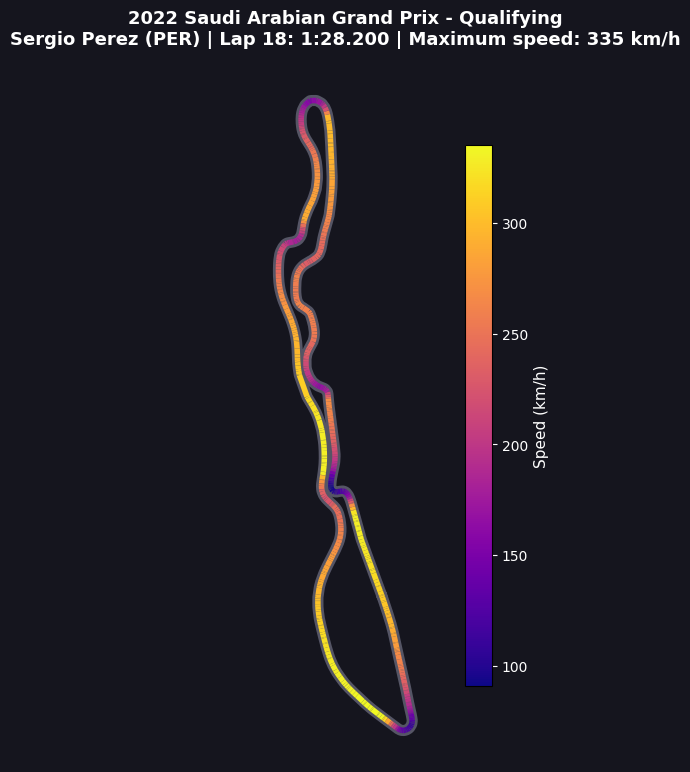

In [ ]:

# ============================================================
# F1 Telemetry Explorer V2 - Stage 2
# Circuit speed map using shared configuration
# ============================================================

import os
import numpy as np
import pandas as pd
import fastf1
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection


class DataProblem(Exception):
    """A clear error for missing or unavailable data."""


def format_lap_time(lap_time):
    """Format a lap time like 1:30.558."""
    total_seconds = lap_time.total_seconds()
    minutes = int(total_seconds // 60)
    seconds = total_seconds - minutes * 60
    return f"{minutes}:{seconds:06.3f}"


try:
    # 1. Check shared configuration
    if not CONFIG_OK:
        raise DataProblem(
            "Fix the Shared Configuration cell before running Stage 2."
        )

    # 2. Load the selected session
    print(
        f"Loading telemetry for {YEAR} {EVENT_NAME} - "
        f"{SESSION_NAMES[SESSION_CODE]}..."
    )

    session = fastf1.get_session(
        YEAR,
        EVENT_NAME,
        SESSION_CODE
    )

    session.load(
        laps=True,
        telemetry=True,
        weather=False,
        messages=False
    )

    # 3. Get the selected driver's laps
    driver_laps = session.laps.pick_drivers(DRIVER_CODE)
    driver_laps = driver_laps.dropna(
        subset=["LapTime"]
    ).copy()

    if driver_laps.empty:
        raise DataProblem(
            f"No timed laps were found for {DRIVER_CODE}."
        )

    # Prefer laps that pass FastF1's accuracy checks
    if "IsAccurate" in driver_laps.columns:
        accurate_mask = driver_laps["IsAccurate"].eq(True)

        # Use accurate laps when at least one is available
        if accurate_mask.any():
            driver_laps = driver_laps.loc[accurate_mask].copy()
            print("Using laps marked accurate by FastF1.")
        else:
            print(
                "No laps passed the accuracy check; "
                "using available timed laps instead."
            )
    else:
        print(
            "The IsAccurate column is unavailable; "
            "using available timed laps."
        )

    if driver_laps.empty:
        raise DataProblem(
            f"No usable timed laps remain for {DRIVER_CODE}."
        )

    # 4. Select the fastest remaining lap
    fastest_lap = driver_laps.pick_fastest()

    if fastest_lap is None or pd.isna(fastest_lap["LapTime"]):
        raise DataProblem(
            f"No usable fastest lap was found for {DRIVER_CODE}."
        )

    lap_time_text = format_lap_time(fastest_lap["LapTime"])
    lap_number = int(fastest_lap["LapNumber"])

    # Find the driver's full name when session results are available
    driver_name = DRIVER_CODE

    if (
        session.results is not None
        and not session.results.empty
        and "Abbreviation" in session.results.columns
        and "FullName" in session.results.columns
    ):
        matching_driver = session.results[
            session.results["Abbreviation"] == DRIVER_CODE
        ]

        if not matching_driver.empty:
            driver_name = matching_driver.iloc[0]["FullName"]

    # 5. Retrieve and check telemetry
    telemetry = fastest_lap.get_telemetry()

    if telemetry is None or telemetry.empty:
        raise DataProblem("No telemetry was available for this lap.")

    required_columns = ["X", "Y", "Speed"]
    missing_columns = [
        col for col in required_columns
        if col not in telemetry.columns
    ]

    if missing_columns:
        raise DataProblem(
            f"Telemetry is missing columns: {missing_columns}"
        )

    # Convert required values to numbers and remove invalid rows
    clean = pd.DataFrame({
        col: pd.to_numeric(telemetry[col], errors="coerce")
        for col in required_columns
    })

    clean = clean.replace([np.inf, -np.inf], np.nan).dropna()

    if len(clean) < 10:
        raise DataProblem(
            f"Only {len(clean)} usable telemetry points were found."
        )

    if clean["X"].nunique() < 2 or clean["Y"].nunique() < 2:
        raise DataProblem(
            "The X/Y coordinates do not form a usable track shape."
        )

    if clean["Speed"].max() <= 0:
        raise DataProblem("No positive speed readings were found.")

    x = clean["X"].to_numpy()
    y = clean["Y"].to_numpy()
    speed = clean["Speed"].to_numpy()

    # 6. Build line segments coloured by speed
    points = np.column_stack((x, y)).reshape(-1, 1, 2)
    segments = np.concatenate(
        [points[:-1], points[1:]],
        axis=1
    )

    fig, ax = plt.subplots(figsize=(11, 9))
    fig.patch.set_facecolor("#15151e")
    ax.set_facecolor("#15151e")

    # Draw a grey outline underneath the racing line
    ax.plot(
        x, y,
        color="#555565",
        linewidth=8,
        solid_capstyle="round",
        zorder=1
    )

    speed_line = LineCollection(
        segments,
        cmap="plasma",
        norm=plt.Normalize(speed.min(), speed.max()),
        linewidth=4,
        zorder=2
    )

    speed_line.set_array(speed[:-1])
    ax.add_collection(speed_line)

    # 7. Format the circuit map
    padding = 0.05 * max(
        x.max() - x.min(),
        y.max() - y.min()
    )

    ax.set_xlim(x.min() - padding, x.max() + padding)
    ax.set_ylim(y.min() - padding, y.max() + padding)
    ax.set_aspect("equal")
    ax.axis("off")

    colorbar = fig.colorbar(
        speed_line,
        ax=ax,
        shrink=0.78,
        pad=0.025
    )

    colorbar.set_label(
        "Speed (km/h)",
        color="white",
        fontsize=11
    )
    colorbar.ax.tick_params(colors="white")

    event_name = session.event["EventName"]

    ax.set_title(
        f"{YEAR} {event_name} - {session.name}\n"
        f"{driver_name} ({DRIVER_CODE}) | "
        f"Lap {lap_number}: {lap_time_text} | "
        f"Maximum speed: {speed.max():.0f} km/h",
        color="white",
        fontsize=13,
        fontweight="bold",
        pad=18
    )

    # 8. Save the image
    output_path = "/content/f1_circuit_speed_map.png"

    fig.savefig(
        output_path,
        dpi=200,
        bbox_inches="tight",
        facecolor=fig.get_facecolor()
    )

    print(f"\nDriver: {driver_name} ({DRIVER_CODE})")
    print(f"Fastest selected lap: {lap_time_text}")
    print(f"Lap number: {lap_number}")
    print(f"Telemetry points: {len(clean)}")
    print(f"Maximum speed: {speed.max():.0f} km/h")
    print(f"Saved circuit map to: {output_path}")

    plt.show()

except DataProblem as problem:
    print(f"\nCould not build the circuit map: {problem}")

except Exception as error:
    print("\nSomething went wrong while building the circuit map.")
    print(f"Error type: {type(error).__name__}")
    print(f"Details: {error}")


core           INFO 	Loading data for Saudi Arabian Grand Prix - Qualifying [v3.9.0]
INFO:fastf1.fastf1.core:Loading data for Saudi Arabian Grand Prix - Qualifying [v3.9.0]
req            INFO 	Using cached data for session_info
INFO:fastf1.fastf1.req:Using cached data for session_info
req            INFO 	Using cached data for driver_info
INFO:fastf1.fastf1.req:Using cached data for driver_info
req            INFO 	Using cached data for session_status_data
INFO:fastf1.fastf1.req:Using cached data for session_status_data
req            INFO 	Using cached data for track_status_data
INFO:fastf1.fastf1.req:Using cached data for track_status_data
req            INFO 	Using cached data for _extended_timing_data
INFO:fastf1.fastf1.req:Using cached data for _extended_timing_data
req            INFO 	Using cached data for timing_app_data
INFO:fastf1.fastf1.req:Using cached data for timing_app_data
core           INFO 	Processing timing data...
INFO:fastf1.fastf1.core:Processing timing data...


Loading telemetry for 2022 Saudi Arabian Grand Prix - Qualifying...


req            INFO 	Using cached data for car_data
INFO:fastf1.fastf1.req:Using cached data for car_data
req            INFO 	Using cached data for position_data
INFO:fastf1.fastf1.req:Using cached data for position_data
core           INFO 	Finished loading data for 20 drivers: ['11', '16', '55', '1', '31', '63', '14', '77', '10', '20', '4', '3', '24', '47', '18', '44', '23', '27', '6', '22']
INFO:fastf1.fastf1.core:Finished loading data for 20 drivers: ['11', '16', '55', '1', '31', '63', '14', '77', '10', '20', '4', '3', '24', '47', '18', '44', '23', '27', '6', '22']


Using laps marked accurate by FastF1.

Driver: Sergio Perez (PER)
Selected lap: 1:28.200
Lap number: 18
Telemetry points: 666
Lap distance: 6094 m
Maximum speed: 335 km/h
Gears used: 3 to 8
Saved telemetry graph to: /content/f1_telemetry_analysis.png


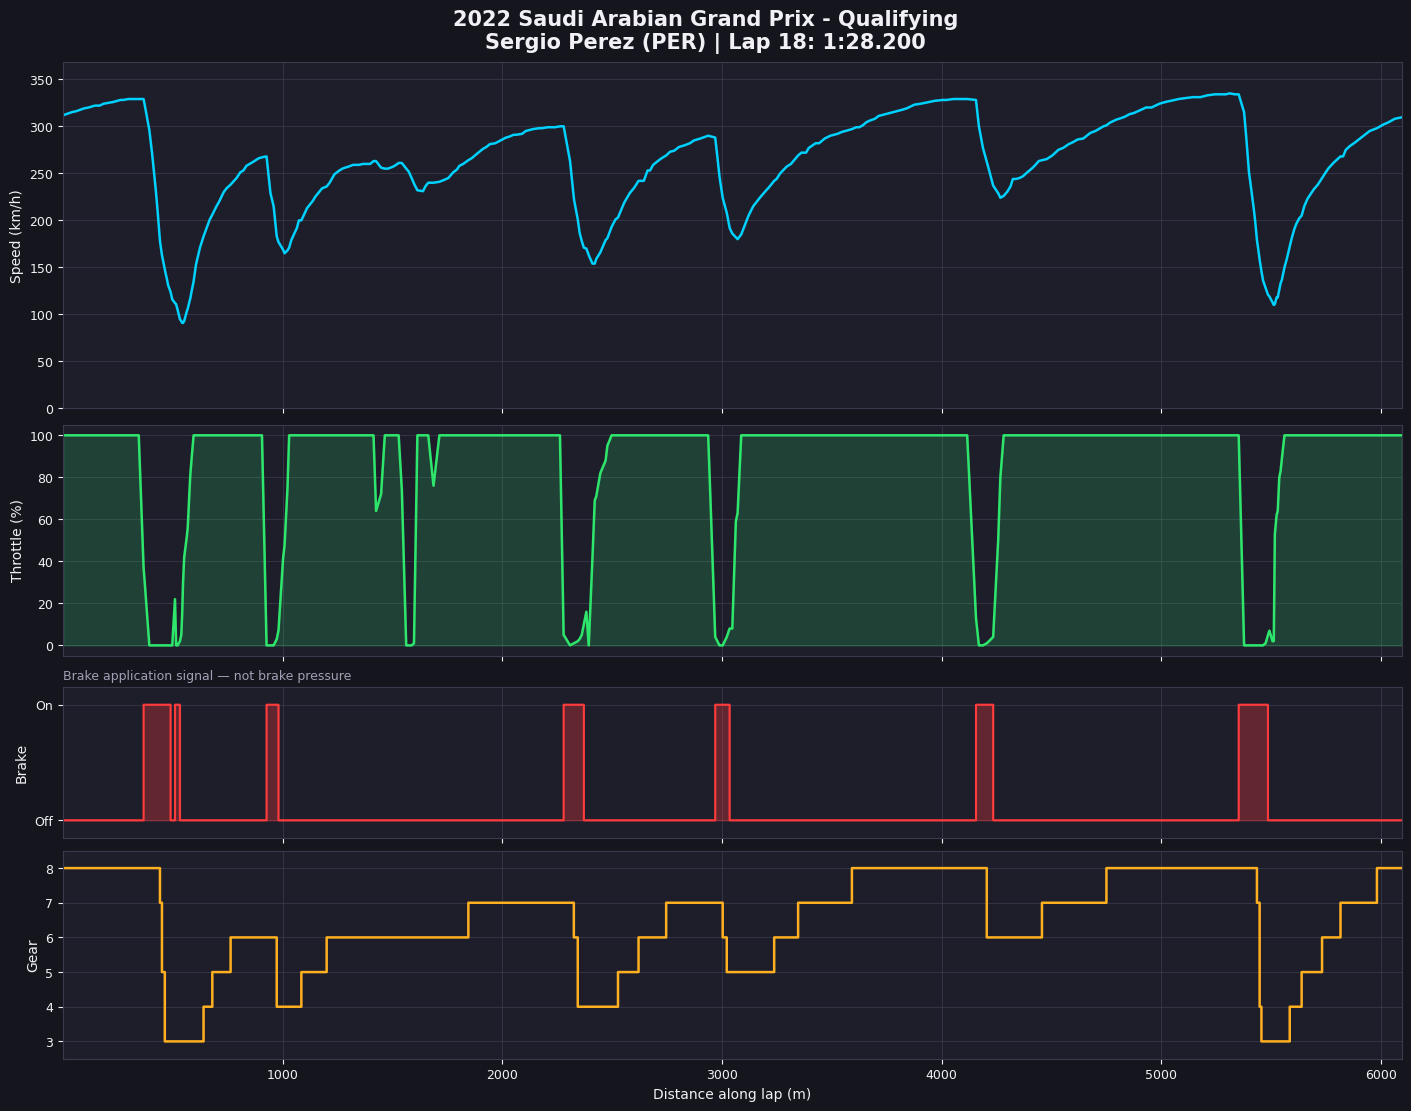

In [ ]:

# ============================================================
# F1 Telemetry Explorer V2 - Stage 3
# Telemetry graphs using shared configuration
# ============================================================

import os
import numpy as np
import pandas as pd
import fastf1
import matplotlib.pyplot as plt


class DataProblem(Exception):
    """A clear error for missing or unavailable data."""


def format_lap_time(lap_time):
    """Format a lap time like 1:30.558."""
    total_seconds = lap_time.total_seconds()
    minutes = int(total_seconds // 60)
    seconds = total_seconds - minutes * 60
    return f"{minutes}:{seconds:06.3f}"


def style_axis(ax, ylabel):
    """Apply a consistent dark motorsport style."""
    ax.set_facecolor("#1e1e2b")
    ax.set_ylabel(ylabel, color="#f0f0f5", fontsize=10)
    ax.grid(True, color="#3a3a4d", linewidth=0.7, alpha=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors="#f0f0f5", labelsize=9)

    for spine in ax.spines.values():
        spine.set_color("#3a3a4d")


try:
    # 1. Check the shared configuration
    if not CONFIG_OK:
        raise DataProblem(
            "Fix the Shared Configuration cell before running Stage 3."
        )

    # 2. Load the selected event and session
    print(
        f"Loading telemetry for {YEAR} {EVENT_NAME} - "
        f"{SESSION_NAMES[SESSION_CODE]}..."
    )

    session = fastf1.get_session(
        YEAR,
        EVENT_NAME,
        SESSION_CODE
    )

    session.load(
        laps=True,
        telemetry=True,
        weather=False,
        messages=False
    )

    # 3. Select the current main driver's laps
    driver_laps = session.laps.pick_drivers(DRIVER_CODE)
    driver_laps = driver_laps.dropna(subset=["LapTime"]).copy()

    if driver_laps.empty:
        raise DataProblem(
            f"No timed laps were found for {DRIVER_CODE}."
        )

    # Prefer laps marked accurate by FastF1
    if "IsAccurate" in driver_laps.columns:
        accurate_mask = driver_laps["IsAccurate"].eq(True)

        if accurate_mask.any():
            driver_laps = driver_laps.loc[accurate_mask].copy()
            print("Using laps marked accurate by FastF1.")
        else:
            print(
                "No laps passed the accuracy check; "
                "using available timed laps instead."
            )
    else:
        print(
            "The IsAccurate column is unavailable; "
            "using available timed laps."
        )

    if driver_laps.empty:
        raise DataProblem(
            f"No usable timed laps remain for {DRIVER_CODE}."
        )

    # Select the fastest remaining lap
    fastest_lap = driver_laps.pick_fastest()

    if fastest_lap is None or pd.isna(fastest_lap["LapTime"]):
        raise DataProblem(
            f"No valid fastest lap was found for {DRIVER_CODE}."
        )

    lap_time_text = format_lap_time(fastest_lap["LapTime"])
    lap_number = int(fastest_lap["LapNumber"])

    # Find the driver's full name when available
    driver_name = DRIVER_CODE

    if (
        session.results is not None
        and not session.results.empty
        and "Abbreviation" in session.results.columns
        and "FullName" in session.results.columns
    ):
        matching = session.results[
            session.results["Abbreviation"] == DRIVER_CODE
        ]

        if not matching.empty:
            driver_name = matching.iloc[0]["FullName"]

    # 4. Retrieve and validate telemetry
    telemetry = fastest_lap.get_telemetry()

    if telemetry is None or telemetry.empty:
        raise DataProblem("No telemetry was available for this lap.")

    required = ["Distance", "Speed", "Throttle", "Brake", "nGear"]
    missing = [col for col in required if col not in telemetry.columns]

    if missing:
        raise DataProblem(
            f"Telemetry is missing columns: {missing}"
        )

    # Convert the Boolean brake signal to 0/1 when necessary
    brake_raw = telemetry["Brake"]

    if pd.api.types.is_bool_dtype(brake_raw):
        brake_values = brake_raw.astype(int)
    else:
        brake_values = pd.to_numeric(brake_raw, errors="coerce")

    # Create a clean numeric table
    clean = pd.DataFrame({
        "Distance": pd.to_numeric(
            telemetry["Distance"], errors="coerce"
        ),
        "Speed": pd.to_numeric(
            telemetry["Speed"], errors="coerce"
        ),
        "Throttle": pd.to_numeric(
            telemetry["Throttle"], errors="coerce"
        ),
        "Brake": pd.to_numeric(
            brake_values, errors="coerce"
        ),
        "nGear": pd.to_numeric(
            telemetry["nGear"], errors="coerce"
        )
    })

    clean = clean.replace([np.inf, -np.inf], np.nan).dropna()

    if len(clean) < 10:
        raise DataProblem(
            f"Only {len(clean)} usable telemetry points were found."
        )

    if clean["Distance"].nunique() < 2:
        raise DataProblem("Distance does not change along the lap.")

    if clean["Speed"].max() <= 0:
        raise DataProblem("No positive speed readings were found.")

    distance = clean["Distance"].to_numpy()
    speed = clean["Speed"].to_numpy()
    throttle = clean["Throttle"].to_numpy()
    brake = clean["Brake"].to_numpy()
    gear = clean["nGear"].to_numpy()

    brake_is_on_off = bool(np.isin(brake, [0, 1]).all())

    # 5. Create four graphs sharing the distance axis
    fig, axes = plt.subplots(
        4, 1,
        figsize=(14, 11),
        sharex=True,
        gridspec_kw={"height_ratios": [3, 2, 1.3, 1.8]},
        constrained_layout=True
    )

    fig.patch.set_facecolor("#15151e")
    speed_ax, throttle_ax, brake_ax, gear_ax = axes

    # Speed
    speed_ax.plot(
        distance, speed,
        color="#00d2ff", linewidth=1.8
    )
    style_axis(speed_ax, "Speed (km/h)")
    speed_ax.set_ylim(0, speed.max() * 1.1)

    # Throttle
    throttle_ax.plot(
        distance, throttle,
        color="#2ee66b", linewidth=1.8
    )
    throttle_ax.fill_between(
        distance, throttle,
        color="#2ee66b", alpha=0.18
    )
    style_axis(throttle_ax, "Throttle (%)")
    throttle_ax.set_ylim(-5, 105)

    # Brake: this is an on/off signal, not brake pressure
    if brake_is_on_off:
        brake_ax.step(
            distance, brake,
            where="post", color="#ff3b3b", linewidth=1.5
        )
        brake_ax.fill_between(
            distance, brake,
            step="post", color="#ff3b3b", alpha=0.3
        )
        style_axis(brake_ax, "Brake")
        brake_ax.set_ylim(-0.15, 1.15)
        brake_ax.set_yticks([0, 1])
        brake_ax.set_yticklabels(["Off", "On"])
        brake_ax.set_title(
            "Brake application signal — not brake pressure",
            loc="left", fontsize=9, color="#a0a0b5"
        )
    else:
        brake_ax.plot(
            distance, brake,
            color="#ff3b3b", linewidth=1.5
        )
        style_axis(brake_ax, "Brake (raw value)")
        brake_ax.set_title(
            "Brake channel contains non-Boolean values",
            loc="left", fontsize=9, color="#a0a0b5"
        )

    # Gear
    gear_ax.step(
        distance, gear,
        where="post", color="#ffb020", linewidth=1.8
    )
    style_axis(gear_ax, "Gear")

    gear_low = int(gear.min())
    gear_high = int(gear.max())
    gear_ax.set_yticks(np.arange(gear_low, gear_high + 1))
    gear_ax.set_ylim(gear_low - 0.5, gear_high + 0.5)

    gear_ax.set_xlim(distance.min(), distance.max())
    gear_ax.set_xlabel("Distance along lap (m)", color="#f0f0f5")

    # Add the selected race, session, driver and lap time to the title
    fig.suptitle(
        f"{YEAR} {session.event['EventName']} - {session.name}\n"
        f"{driver_name} ({DRIVER_CODE}) | "
        f"Lap {lap_number}: {lap_time_text}",
        color="#f0f0f5",
        fontsize=15,
        fontweight="bold"
    )

    # 6. Print the summary and save the graph
    output_path = "/content/f1_telemetry_analysis.png"

    fig.savefig(
        output_path,
        dpi=200,
        bbox_inches="tight",
        facecolor=fig.get_facecolor()
    )

    print(f"\nDriver: {driver_name} ({DRIVER_CODE})")
    print(f"Selected lap: {lap_time_text}")
    print(f"Lap number: {lap_number}")
    print(f"Telemetry points: {len(clean)}")
    print(f"Lap distance: {distance.max():.0f} m")
    print(f"Maximum speed: {speed.max():.0f} km/h")
    print(f"Gears used: {gear_low} to {gear_high}")
    print(f"Saved telemetry graph to: {output_path}")

    plt.show()

except DataProblem as problem:
    print(f"\nCould not build the telemetry graphs: {problem}")

except Exception as error:
    print("\nSomething went wrong while creating Stage 3.")
    print(f"Error type: {type(error).__name__}")
    print(f"Details: {error}")


core           INFO 	Loading data for Saudi Arabian Grand Prix - Qualifying [v3.9.0]
INFO:fastf1.fastf1.core:Loading data for Saudi Arabian Grand Prix - Qualifying [v3.9.0]
req            INFO 	Using cached data for session_info
INFO:fastf1.fastf1.req:Using cached data for session_info
req            INFO 	Using cached data for driver_info
INFO:fastf1.fastf1.req:Using cached data for driver_info
req            INFO 	Using cached data for session_status_data
INFO:fastf1.fastf1.req:Using cached data for session_status_data
req            INFO 	Using cached data for track_status_data
INFO:fastf1.fastf1.req:Using cached data for track_status_data
req            INFO 	Using cached data for _extended_timing_data
INFO:fastf1.fastf1.req:Using cached data for _extended_timing_data
req            INFO 	Using cached data for timing_app_data
INFO:fastf1.fastf1.req:Using cached data for timing_app_data
core           INFO 	Processing timing data...
INFO:fastf1.fastf1.core:Processing timing data...


Loading 2022 Saudi Arabian Grand Prix - Qualifying...


req            INFO 	Using cached data for car_data
INFO:fastf1.fastf1.req:Using cached data for car_data
req            INFO 	Using cached data for position_data
INFO:fastf1.fastf1.req:Using cached data for position_data
core           INFO 	Finished loading data for 20 drivers: ['11', '16', '55', '1', '31', '63', '14', '77', '10', '20', '4', '3', '24', '47', '18', '44', '23', '27', '6', '22']
INFO:fastf1.fastf1.core:Finished loading data for 20 drivers: ['11', '16', '55', '1', '31', '63', '14', '77', '10', '20', '4', '3', '24', '47', '18', '44', '23', '27', '6', '22']



Sergio Perez (PER): 1:28.200
Charles Leclerc (LEC): 1:28.225
Lap difference (LEC - PER): +0.025 seconds
Sergio Perez set the faster lap.
Estimated gap at the end of the shared distance: -0.110 seconds
Note: The time-gap curve is estimated from distance-aligned telemetry, not an official FIA timing calculation.
Saved comparison to: /content/f1_driver_comparison.png


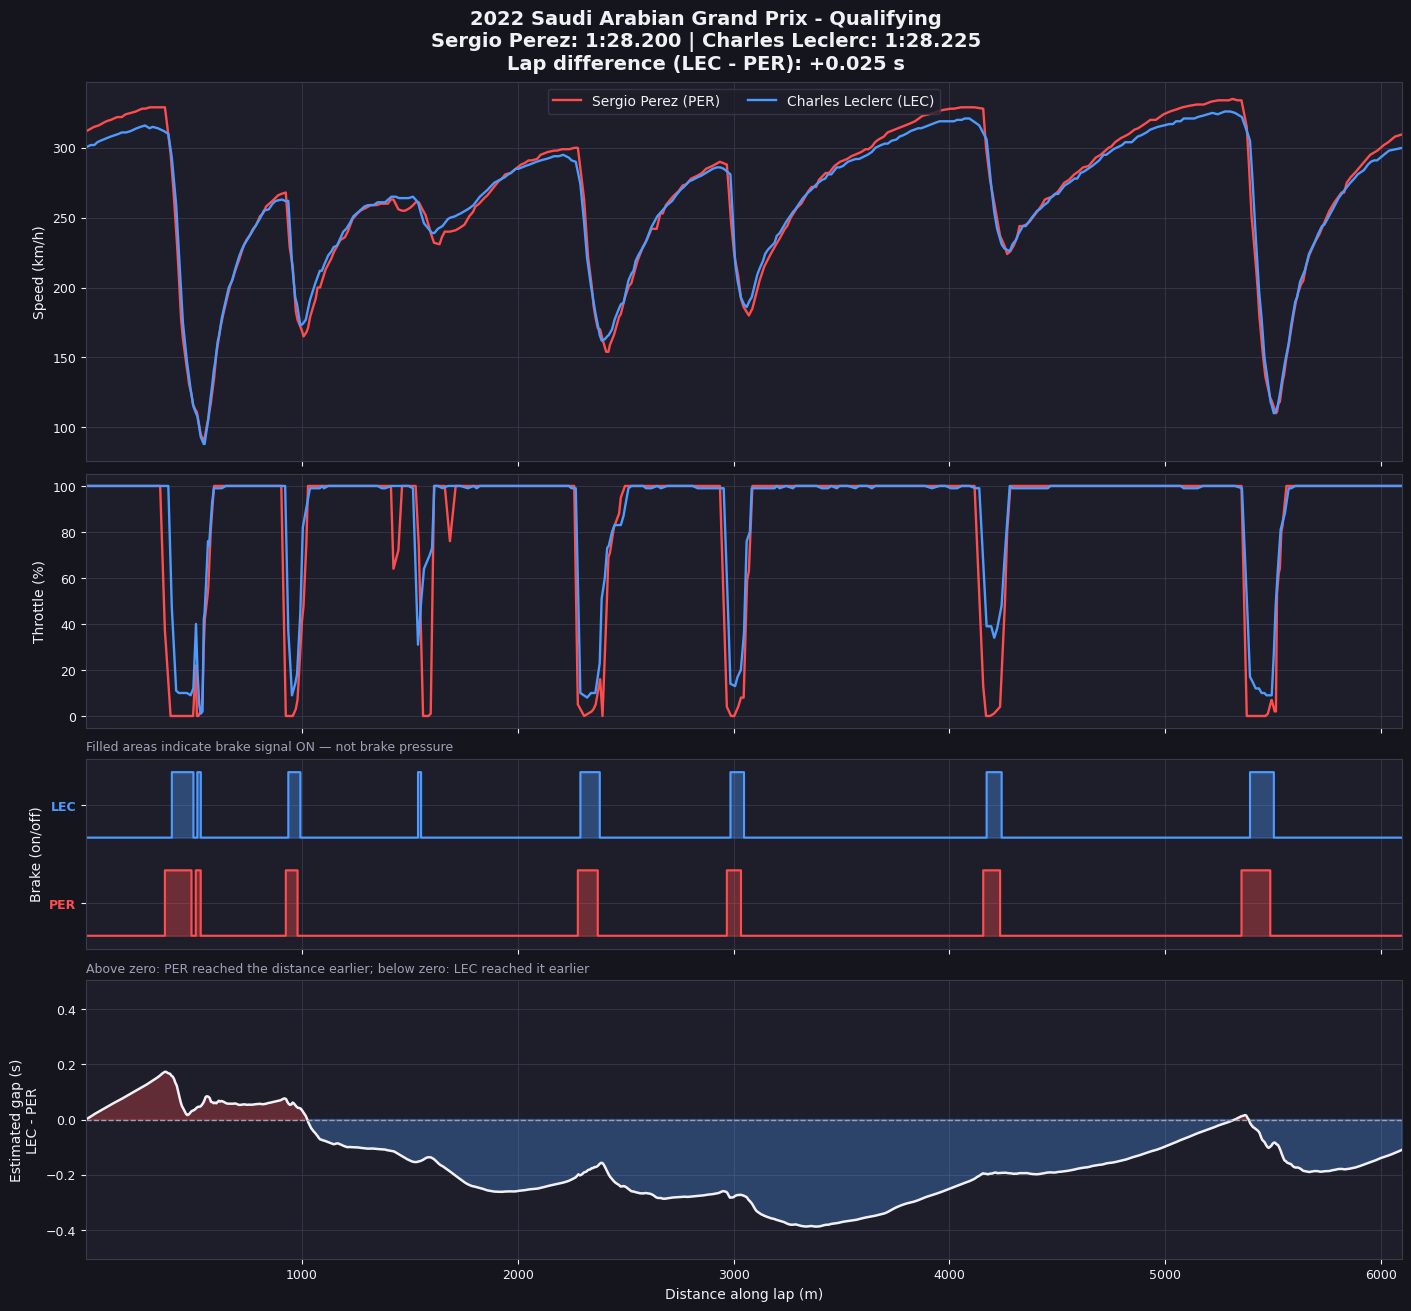

In [ ]:

# ============================================================
# F1 Telemetry Explorer V2 - Stage 4
# Driver comparison using shared configuration
# ============================================================

import os
import numpy as np
import pandas as pd
import fastf1
import matplotlib.pyplot as plt


class DataProblem(Exception):
    """A clear error for missing or unavailable data."""


def format_lap_time(lap_time):
    """Format a lap time like 1:30.558."""
    total_seconds = lap_time.total_seconds()
    minutes = int(total_seconds // 60)
    seconds = total_seconds - minutes * 60
    return f"{minutes}:{seconds:06.3f}"


def get_driver_name(session, code):
    """Get the driver's full name when available."""
    try:
        results = session.results

        if (
            results is not None
            and not results.empty
            and {"Abbreviation", "FullName"}.issubset(results.columns)
        ):
            matching = results[
                results["Abbreviation"] == code
            ]

            if not matching.empty:
                return matching.iloc[0]["FullName"]

    except Exception:
        pass

    return code


def get_fastest_valid_lap(session, code):
    """Select a driver's fastest timed lap, preferring accurate laps."""
    laps = session.laps.pick_drivers(code)
    laps = laps.dropna(subset=["LapTime"]).copy()

    if laps.empty:
        raise DataProblem(f"No timed laps were found for {code}.")

    # Prefer laps marked accurate by FastF1, if available.
    if "IsAccurate" in laps.columns:
        accurate_mask = laps["IsAccurate"].eq(True)

        if accurate_mask.any():
            laps = laps.loc[accurate_mask].copy()

    if laps.empty:
        raise DataProblem(f"No usable laps were found for {code}.")

    fastest_lap = laps.pick_fastest()

    if fastest_lap is None or pd.isna(fastest_lap["LapTime"]):
        raise DataProblem(f"No usable fastest lap was found for {code}.")

    return fastest_lap


def prepare_driver_data(lap, code):
    """Retrieve and clean a driver's telemetry."""
    telemetry = lap.get_telemetry()

    if telemetry is None or telemetry.empty:
        raise DataProblem(f"No telemetry was available for {code}.")

    required = ["Distance", "Speed", "Throttle", "Brake", "Time"]

    missing = [
        col for col in required
        if col not in telemetry.columns
    ]

    if missing:
        raise DataProblem(
            f"{code} telemetry is missing columns: {missing}"
        )

    # Convert the brake signal to 0/1 if it is Boolean.
    brake_raw = telemetry["Brake"]

    if pd.api.types.is_bool_dtype(brake_raw):
        brake_values = brake_raw.astype(int)
    else:
        brake_values = pd.to_numeric(
            brake_raw, errors="coerce"
        )

    # Convert timestamps to elapsed seconds relative to this lap's
    # first usable telemetry timestamp.
    time_values = pd.to_timedelta(
        telemetry["Time"], errors="coerce"
    )

    valid_times = time_values.dropna()

    if valid_times.empty:
        raise DataProblem(f"No usable telemetry timestamps for {code}.")

    elapsed_seconds = (
        time_values - valid_times.iloc[0]
    ).dt.total_seconds()

    data = pd.DataFrame({
        "Distance": pd.to_numeric(
            telemetry["Distance"], errors="coerce"
        ).to_numpy(),
        "Speed": pd.to_numeric(
            telemetry["Speed"], errors="coerce"
        ).to_numpy(),
        "Throttle": pd.to_numeric(
            telemetry["Throttle"], errors="coerce"
        ).to_numpy(),
        "Brake": pd.to_numeric(
            brake_values, errors="coerce"
        ).to_numpy(),
        "ElapsedSeconds": elapsed_seconds.to_numpy()
    })

    # Remove missing and infinite observations.
    data = data.replace([np.inf, -np.inf], np.nan).dropna()

    if len(data) < 10:
        raise DataProblem(
            f"Only {len(data)} usable telemetry points for {code}."
        )

    # Sort by distance and combine duplicate distance readings.
    data = data.sort_values("Distance")

    data = data.groupby(
        "Distance", as_index=False
    ).agg({
        "Speed": "mean",
        "Throttle": "mean",
        "Brake": "max",
        "ElapsedSeconds": "mean"
    })

    if len(data) < 10:
        raise DataProblem(
            f"Too few distinct distance points for {code}."
        )

    if data["Distance"].max() <= data["Distance"].min():
        raise DataProblem(f"Distance does not vary for {code}.")

    if data["Speed"].max() <= 0:
        raise DataProblem(f"No positive speed readings for {code}.")

    if data["ElapsedSeconds"].max() <= 0:
        raise DataProblem(f"Telemetry time does not increase for {code}.")

    return data


def style_axis(ax, ylabel):
    """Apply a consistent dark motorsport style."""
    ax.set_facecolor("#1e1e2b")
    ax.set_ylabel(ylabel, color="#f0f0f5", fontsize=10)
    ax.grid(True, color="#3a3a4d", linewidth=0.7, alpha=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors="#f0f0f5", labelsize=9)

    for spine in ax.spines.values():
        spine.set_color("#3a3a4d")


try:
    # 1. Validate the shared configuration.
    if not CONFIG_OK:
        raise DataProblem(
            "Fix the Shared Configuration cell before Stage 4."
        )

    if DRIVER_1 == DRIVER_2:
        raise DataProblem(
            "Choose two different drivers in the configuration."
        )

    print(
        f"Loading {YEAR} {EVENT_NAME} - "
        f"{SESSION_NAMES[SESSION_CODE]}..."
    )

    # 2. Load the selected event and session.
    session = fastf1.get_session(
        YEAR,
        EVENT_NAME,
        SESSION_CODE
    )

    session.load(
        laps=True,
        telemetry=True,
        weather=False,
        messages=False
    )

    # 3. Find the fastest usable lap for each selected driver.
    lap_1 = get_fastest_valid_lap(session, DRIVER_1)
    lap_2 = get_fastest_valid_lap(session, DRIVER_2)

    name_1 = get_driver_name(session, DRIVER_1)
    name_2 = get_driver_name(session, DRIVER_2)

    time_1 = lap_1["LapTime"]
    time_2 = lap_2["LapTime"]

    time_1_text = format_lap_time(time_1)
    time_2_text = format_lap_time(time_2)

    seconds_1 = time_1.total_seconds()
    seconds_2 = time_2.total_seconds()

    # Positive difference means Driver 1 set the faster lap.
    lap_difference = seconds_2 - seconds_1

    # 4. Retrieve and clean both telemetry traces.
    data_1 = prepare_driver_data(lap_1, DRIVER_1)
    data_2 = prepare_driver_data(lap_2, DRIVER_2)

    # 5. Align elapsed times over a shared distance range.
    grid_start = max(
        data_1["Distance"].min(),
        data_2["Distance"].min()
    )

    grid_end = min(
        data_1["Distance"].max(),
        data_2["Distance"].max()
    )

    if grid_end - grid_start < 100:
        raise DataProblem(
            "The two laps have too little common distance to compare."
        )

    distance_grid = np.linspace(grid_start, grid_end, 1000)

    elapsed_1 = np.interp(
        distance_grid,
        data_1["Distance"],
        data_1["ElapsedSeconds"]
    )

    elapsed_2 = np.interp(
        distance_grid,
        data_2["Distance"],
        data_2["ElapsedSeconds"]
    )

    # Positive: Driver 1 reached a given distance earlier.
    time_gap = elapsed_2 - elapsed_1

    if not np.isfinite(time_gap).all():
        raise DataProblem("The estimated time-gap values are invalid.")

    # 6. Create the four comparison graphs.
    color_1 = "#ff4d4d"
    color_2 = "#4d9bff"
    background = "#15151e"
    panel = "#1e1e2b"

    fig, axes = plt.subplots(
        4, 1,
        figsize=(14, 13),
        sharex=True,
        gridspec_kw={"height_ratios": [3, 2, 1.5, 2.2]},
        constrained_layout=True
    )

    fig.patch.set_facecolor(background)

    speed_ax, throttle_ax, brake_ax, gap_ax = axes

    # Panel 1: Speed.
    speed_ax.plot(
        data_1["Distance"], data_1["Speed"],
        color=color_1, linewidth=1.7,
        label=f"{name_1} ({DRIVER_1})"
    )

    speed_ax.plot(
        data_2["Distance"], data_2["Speed"],
        color=color_2, linewidth=1.7,
        label=f"{name_2} ({DRIVER_2})"
    )

    style_axis(speed_ax, "Speed (km/h)")

    speed_ax.legend(
        loc="upper center",
        ncol=2,
        facecolor=panel,
        edgecolor="#3a3a4d",
        labelcolor="#f0f0f5"
    )

    # Panel 2: Throttle.
    throttle_ax.plot(
        data_1["Distance"], data_1["Throttle"],
        color=color_1, linewidth=1.7
    )

    throttle_ax.plot(
        data_2["Distance"], data_2["Throttle"],
        color=color_2, linewidth=1.7
    )

    style_axis(throttle_ax, "Throttle (%)")
    throttle_ax.set_ylim(-5, 105)

    # Panel 3: Brake application.
    brake_is_on_off = all(
        np.isin(data["Brake"].to_numpy(), [0, 1]).all()
        for data in (data_1, data_2)
    )

    if brake_is_on_off:
        lane_1 = 0.0
        lane_2 = 1.5

        for driver_data, lane, color in [
            (data_1, lane_1, color_1),
            (data_2, lane_2, color_2)
        ]:
            values = driver_data["Brake"].to_numpy() + lane

            brake_ax.step(
                driver_data["Distance"], values,
                where="post", color=color, linewidth=1.5
            )

            brake_ax.fill_between(
                driver_data["Distance"], lane, values,
                step="post", color=color, alpha=0.35
            )

        style_axis(brake_ax, "Brake (on/off)")
        brake_ax.set_ylim(-0.2, 2.7)
        brake_ax.set_yticks([0.5, 2.0])
        brake_ax.set_yticklabels([DRIVER_1, DRIVER_2])

        for label, color in zip(
            brake_ax.get_yticklabels(), [color_1, color_2]
        ):
            label.set_color(color)
            label.set_fontweight("bold")

        brake_ax.set_title(
            "Filled areas indicate brake signal ON — not brake pressure",
            loc="left", fontsize=9, color="#a0a0b5"
        )

    else:
        brake_ax.plot(
            data_1["Distance"], data_1["Brake"],
            color=color_1, linewidth=1.5, label=DRIVER_1
        )

        brake_ax.plot(
            data_2["Distance"], data_2["Brake"],
            color=color_2, linewidth=1.5, label=DRIVER_2
        )

        style_axis(brake_ax, "Brake (raw values)")

        brake_ax.legend(
            facecolor=panel,
            labelcolor="#f0f0f5"
        )

        brake_ax.set_title(
            "Brake channel shown as raw values",
            loc="left", fontsize=9, color="#a0a0b5"
        )

    # Panel 4: Estimated time gap.
    gap_ax.plot(
        distance_grid, time_gap,
        color="#f0f0f5", linewidth=1.8
    )

    gap_ax.fill_between(
        distance_grid, time_gap, 0,
        where=time_gap >= 0,
        interpolate=True,
        color=color_1,
        alpha=0.3
    )

    gap_ax.fill_between(
        distance_grid, time_gap, 0,
        where=time_gap < 0,
        interpolate=True,
        color=color_2,
        alpha=0.3
    )

    gap_ax.axhline(
        0, color="#a0a0b5",
        linestyle="--", linewidth=1
    )

    style_axis(
        gap_ax,
        f"Estimated gap (s)\n{DRIVER_2} - {DRIVER_1}"
    )

    gap_limit = max(float(np.max(np.abs(time_gap))) * 1.3, 0.05)
    gap_ax.set_ylim(-gap_limit, gap_limit)

    gap_ax.set_title(
        f"Above zero: {DRIVER_1} reached the distance earlier; "
        f"below zero: {DRIVER_2} reached it earlier",
        loc="left", fontsize=9, color="#a0a0b5"
    )

    gap_ax.set_xlim(grid_start, grid_end)
    gap_ax.set_xlabel("Distance along lap (m)", color="#f0f0f5")

    event_name = session.event["EventName"]

    fig.suptitle(
        f"{YEAR} {event_name} - {session.name}\n"
        f"{name_1}: {time_1_text} | {name_2}: {time_2_text}\n"
        f"Lap difference ({DRIVER_2} - {DRIVER_1}): "
        f"{lap_difference:+.3f} s",
        color="#f0f0f5",
        fontsize=14,
        fontweight="bold"
    )

    # 7. Print the results and save the comparison.
    output_path = "/content/f1_driver_comparison.png"

    fig.savefig(
        output_path,
        dpi=200,
        bbox_inches="tight",
        facecolor=fig.get_facecolor()
    )

    print(f"\n{ name_1 } ({DRIVER_1}): {time_1_text}")
    print(f"{ name_2 } ({DRIVER_2}): {time_2_text}")
    print(
        f"Lap difference ({DRIVER_2} - {DRIVER_1}): "
        f"{lap_difference:+.3f} seconds"
    )

    if lap_difference > 0:
        print(f"{name_1} set the faster lap.")
    elif lap_difference < 0:
        print(f"{name_2} set the faster lap.")
    else:
        print("The recorded lap times are identical.")

    print(
        f"Estimated gap at the end of the shared distance: "
        f"{time_gap[-1]:+.3f} seconds"
    )

    print(
        "Note: The time-gap curve is estimated from distance-aligned "
        "telemetry, not an official FIA timing calculation."
    )

    print(f"Saved comparison to: {output_path}")

    plt.show()

except DataProblem as problem:
    print(f"\nCould not build the driver comparison: {problem}")

except Exception as error:
    print("\nSomething went wrong while creating Stage 4.")
    print(f"Error type: {type(error).__name__}")
    print(f"Details: {error}")



In [ ]:
import os

output_files = [
    "/content/f1_circuit_speed_map.png",
    "/content/f1_telemetry_analysis.png",
    "/content/f1_driver_comparison.png"
]

for file in output_files:
    if os.path.exists(file):
        print("✅ FOUND:", os.path.basename(file))
    else:
        print("❌ MISSING:", os.path.basename(file))

✅ FOUND: f1_circuit_speed_map.png
✅ FOUND: f1_telemetry_analysis.png
✅ FOUND: f1_driver_comparison.png


In [ ]:
import zipfile
from google.colab import files
import os

output_files = [
    "/content/f1_circuit_speed_map.png",
    "/content/f1_telemetry_analysis.png",
    "/content/f1_driver_comparison.png"
]

zip_path = "/content/f1_telemetry_outputs.zip"

with zipfile.ZipFile(zip_path, "w") as archive:
    for file in output_files:
        archive.write(file, arcname=os.path.basename(file))

print("✅ All three graphs added to the ZIP.")
files.download(zip_path)

✅ All three graphs added to the ZIP.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>